# GAMES + TEST

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [ ]:
import numpy as np

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
train = pd.read_csv(r'/content/drive/MyDrive/KUBIG 2022 이수찬/2차 분류 예측 프로젝트/train.csv')
turns =pd.read_csv(r'/content/drive/MyDrive/KUBIG 2022 이수찬/2차 분류 예측 프로젝트/turns.csv')
games = pd.read_csv(r'/content/drive/MyDrive/KUBIG 2022 이수찬/2차 분류 예측 프로젝트/games.csv')
test= pd.read_csv(r'/content/drive/MyDrive/KUBIG 2022 이수찬/2차 분류 예측 프로젝트/test.csv')

In [ ]:
turns['turn_type'].value_counts()

Play             1872864
End                67987
Exchange           48997
Pass                8065
Timeout             4143
Challenge           2571
Six-Zero Rule        476
Name: turn_type, dtype: int64

In [ ]:
games['winner'].value_counts()

 0    46713
 1    25792
-1      268
Name: winner, dtype: int64

In [ ]:
new= pd.merge(train, games, "outer", on='game_id')

In [ ]:
new = new[new["nickname"].isna() != True]

In [ ]:
new

,game_id,nickname,score,rating,first,time_control_name,game_end_reason,winner,created_at,lexicon,initial_time_seconds,increment_seconds,rating_mode,max_overtime_minutes,game_duration_seconds
0,1,BetterBot,335.0,1637.0,BetterBot,regular,STANDARD,1,2022-08-26 03:38:49,NWL20,1200,0,CASUAL,1,674.844274
1,1,stevy,429.0,1500.0,BetterBot,regular,STANDARD,1,2022-08-26 03:38:49,NWL20,1200,0,CASUAL,1,674.844274
2,3,davidavid,440.0,1811.0,BetterBot,regular,STANDARD,1,2022-09-04 08:04:27,CSW21,900,0,RATED,5,492.268262
3,3,BetterBot,318.0,2071.0,BetterBot,regular,STANDARD,1,2022-09-04 08:04:27,CSW21,900,0,RATED,5,492.268262
4,4,Inandoutworker,119.0,1473.0,BetterBot,regular,RESIGNED,0,2022-09-12 02:36:19,CSW21,3600,0,CASUAL,1,350.861141
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100815,72771,HastyBot,393.0,1614.0,HastyBot,regular,STANDARD,0,2022-09-19 03:28:44,ECWL,900,0,CASUAL,10,236.133634
100816,72772,BetterBot,442.0,1674.0,Gtowngrad,regular,STANDARD,0,2022-08-31 15:57:38,NWL20,900,0,RATED,1,681.370077
100817,72772,Gtowngrad,388.0,1364.0,Gtowngrad,regular,STANDARD,0,2022-08-31 15:57:38,NWL20,900,0,RATED,1,681.370077
100818,72773,adola,383.0,2075.0,HastyBot,regular,STANDARD,1,2022-08-27 09:13:08,CSW21,1200,0,RATED,1,719.720262


In [ ]:
train_bots = new[new['nickname'].isin(['BetterBot','HastyBot','STEEBot'])]

In [ ]:
train_players = new[new['nickname'].isin(['BetterBot','HastyBot','STEEBot']) == False]

In [ ]:
train_players

,game_id,nickname,score,rating,first,time_control_name,game_end_reason,winner,created_at,lexicon,initial_time_seconds,increment_seconds,rating_mode,max_overtime_minutes,game_duration_seconds
1,1,stevy,429.0,1500.0,BetterBot,regular,STANDARD,1,2022-08-26 03:38:49,NWL20,1200,0,CASUAL,1,674.844274
2,3,davidavid,440.0,1811.0,BetterBot,regular,STANDARD,1,2022-09-04 08:04:27,CSW21,900,0,RATED,5,492.268262
4,4,Inandoutworker,119.0,1473.0,BetterBot,regular,RESIGNED,0,2022-09-12 02:36:19,CSW21,3600,0,CASUAL,1,350.861141
6,5,stevy,325.0,1500.0,STEEBot,regular,STANDARD,0,2022-09-06 04:31:36,NWL20,1200,0,CASUAL,1,642.688722
8,6,HivinD,378.0,2029.0,HivinD,regular,STANDARD,0,2022-08-21 14:56:35,CSW21,900,0,RATED,1,426.950541
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100810,72767,HAYDEN,340.0,1395.0,BetterBot,regular,TIME,0,2022-09-05 04:35:56,CSW21,3600,0,CASUAL,1,3669.988413
100813,72770,samsiah06,97.0,1332.0,HastyBot,regular,TIME,0,2022-09-04 00:13:24,CSW21,3600,0,RATED,1,3662.659287
100814,72771,BB-8,390.0,1500.0,HastyBot,regular,STANDARD,0,2022-09-19 03:28:44,ECWL,900,0,CASUAL,10,236.133634
100817,72772,Gtowngrad,388.0,1364.0,Gtowngrad,regular,STANDARD,0,2022-08-31 15:57:38,NWL20,900,0,RATED,1,681.370077


In [ ]:
train_bots

,game_id,nickname,score,rating,first,time_control_name,game_end_reason,winner,created_at,lexicon,initial_time_seconds,increment_seconds,rating_mode,max_overtime_minutes,game_duration_seconds
0,1,BetterBot,335.0,1637.0,BetterBot,regular,STANDARD,1,2022-08-26 03:38:49,NWL20,1200,0,CASUAL,1,674.844274
3,3,BetterBot,318.0,2071.0,BetterBot,regular,STANDARD,1,2022-09-04 08:04:27,CSW21,900,0,RATED,5,492.268262
5,4,BetterBot,478.0,1936.0,BetterBot,regular,RESIGNED,0,2022-09-12 02:36:19,CSW21,3600,0,CASUAL,1,350.861141
7,5,STEEBot,427.0,1844.0,STEEBot,regular,STANDARD,0,2022-09-06 04:31:36,NWL20,1200,0,CASUAL,1,642.688722
9,6,STEEBot,427.0,2143.0,HivinD,regular,STANDARD,0,2022-08-21 14:56:35,CSW21,900,0,RATED,1,426.950541
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100811,72767,BetterBot,414.0,1952.0,BetterBot,regular,TIME,0,2022-09-05 04:35:56,CSW21,3600,0,CASUAL,1,3669.988413
100812,72770,HastyBot,590.0,2237.0,HastyBot,regular,TIME,0,2022-09-04 00:13:24,CSW21,3600,0,RATED,1,3662.659287
100815,72771,HastyBot,393.0,1614.0,HastyBot,regular,STANDARD,0,2022-09-19 03:28:44,ECWL,900,0,CASUAL,10,236.133634
100816,72772,BetterBot,442.0,1674.0,Gtowngrad,regular,STANDARD,0,2022-08-31 15:57:38,NWL20,900,0,RATED,1,681.370077


In [ ]:
train_bots.columns

Index(['game_id', 'nickname', 'score', 'rating', 'first', 'time_control_name',
       'game_end_reason', 'winner', 'created_at', 'lexicon',
       'initial_time_seconds', 'increment_seconds', 'rating_mode',
       'max_overtime_minutes', 'game_duration_seconds'],
      dtype='object')

In [ ]:
train_bots['opponent'] = train_bots['nickname']

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """Entry point for launching an IPython kernel.


In [ ]:
train_bots['opp_rating'] = train_bots['rating']

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """Entry point for launching an IPython kernel.


In [ ]:
train_bots['opp_score'] = train_bots['score']

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """Entry point for launching an IPython kernel.


In [ ]:
train_bots.drop(['nickname', 'score', 'rating', 'first', 'time_control_name',
       'game_end_reason', 'winner', 'created_at', 'lexicon',
       'initial_time_seconds', 'increment_seconds', 'rating_mode',
       'max_overtime_minutes', 'game_duration_seconds'],axis = 1,inplace=True)

/usr/local/lib/python3.7/dist-packages/pandas/core/frame.py:4913: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  errors=errors,


In [ ]:
train_bots

,game_id,opponent,opp_rating,opp_score
0,1,BetterBot,1637.0,335.0
3,3,BetterBot,2071.0,318.0
5,4,BetterBot,1936.0,478.0
7,5,STEEBot,1844.0,427.0
9,6,STEEBot,2143.0,427.0
...,...,...,...,...
100811,72767,BetterBot,1952.0,414.0
100812,72770,HastyBot,2237.0,590.0
100815,72771,HastyBot,1614.0,393.0
100816,72772,BetterBot,1674.0,442.0


In [ ]:
final_train = pd.merge(train_players,train_bots,"outer",on = "game_id")

In [ ]:
final_train.drop(['initial_time_seconds','increment_seconds','game_duration_seconds','created_at'],axis=1,inplace=True)

In [ ]:
final_train['first'] = np.where(final_train['nickname'] == final_train['first'],1,0)

In [ ]:
final_train['winner'] = np.where(final_train['first'] == final_train['winner'],1,0)

In [ ]:
final_train

,game_id,nickname,score,rating,first,time_control_name,game_end_reason,winner,lexicon,rating_mode,max_overtime_minutes,opponent,opp_rating,opp_score
0,1,stevy,429.0,1500.0,0,regular,STANDARD,0,NWL20,CASUAL,1,BetterBot,1637.0,335.0
1,3,davidavid,440.0,1811.0,0,regular,STANDARD,0,CSW21,RATED,5,BetterBot,2071.0,318.0
2,4,Inandoutworker,119.0,1473.0,0,regular,RESIGNED,1,CSW21,CASUAL,1,BetterBot,1936.0,478.0
3,5,stevy,325.0,1500.0,0,regular,STANDARD,1,NWL20,CASUAL,1,STEEBot,1844.0,427.0
4,6,HivinD,378.0,2029.0,1,regular,STANDARD,0,CSW21,RATED,1,STEEBot,2143.0,427.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50405,72767,HAYDEN,340.0,1395.0,0,regular,TIME,1,CSW21,CASUAL,1,BetterBot,1952.0,414.0
50406,72770,samsiah06,97.0,1332.0,0,regular,TIME,1,CSW21,RATED,1,HastyBot,2237.0,590.0
50407,72771,BB-8,390.0,1500.0,0,regular,STANDARD,1,ECWL,CASUAL,10,HastyBot,1614.0,393.0
50408,72772,Gtowngrad,388.0,1364.0,1,regular,STANDARD,0,NWL20,RATED,1,BetterBot,1674.0,442.0


In [ ]:
new1= pd.merge(test, games, "outer", on='game_id')

In [ ]:
new1 = new1[new1["nickname"].isna() != True]

In [ ]:
test_bots = new1[new1['nickname'].isin(['BetterBot','HastyBot','STEEBot'])]
test_players = new1[new1['nickname'].isin(['BetterBot','HastyBot','STEEBot']) == False]

test_bots['opponent'] = test_bots['nickname']
test_bots['opp_rating'] = test_bots['rating']
test_bots['opp_score'] = test_bots['score']

test_bots.drop(['nickname', 'score', 'rating', 'first', 'time_control_name',
       'game_end_reason', 'winner', 'created_at', 'lexicon',
       'initial_time_seconds', 'increment_seconds', 'rating_mode',
       'max_overtime_minutes', 'game_duration_seconds'],axis = 1,inplace=True)

final_test = pd.merge(test_players,test_bots,"outer",on = "game_id")
final_test.drop(['initial_time_seconds','increment_seconds','game_duration_seconds','created_at'],axis=1,inplace=True)
final_test['first'] = np.where(final_test['nickname'] == final_test['first'],1,0)
final_test['winner'] = np.where(final_test['first'] == final_test['winner'],1,0)

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  after removing the cwd from sys.path.
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation:

In [ ]:
final_test

,game_id,nickname,score,rating,first,time_control_name,game_end_reason,winner,lexicon,rating_mode,max_overtime_minutes,opponent,opp_rating,opp_score
0,2,Super,488.0,NaN,1,regular,STANDARD,1,CSW21,RATED,1,BetterBot,2000.0,401.0
1,7,Priya1,379.0,NaN,1,regular,STANDARD,1,CSW21,RATED,1,STEEBot,2082.0,377.0
2,11,TileRunner,462.0,NaN,1,regular,STANDARD,1,NWL20,CASUAL,1,STEEBot,1829.0,334.0
3,14,Anfield223,359.0,NaN,0,regular,STANDARD,1,CSW21,RATED,1,STEEBot,2136.0,403.0
4,27,friesbasil,456.0,NaN,1,regular,STANDARD,1,CSW21,RATED,1,HastyBot,2258.0,453.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22358,72760,thams,494.0,NaN,0,regular,STANDARD,0,CSW21,RATED,3,STEEBot,2030.0,386.0
22359,72761,hulkbuster,232.0,NaN,1,regular,STANDARD,0,CSW21,RATED,1,BetterBot,2044.0,469.0
22360,72762,kyjo55555,367.0,NaN,1,regular,STANDARD,1,NWL20,CASUAL,1,BetterBot,1710.0,299.0
22361,72768,Maximilian,357.0,NaN,0,regular,STANDARD,1,CSW21,RATED,1,HastyBot,2356.0,524.0


In [ ]:
final_test[final_test['game_end_reason'] == 'RESIGNED']

,game_id,nickname,score,rating,first,time_control_name,game_end_reason,winner,lexicon,rating_mode,max_overtime_minutes,opponent,opp_rating,opp_score
20,78,strataji,224.0,NaN,0,regular,RESIGNED,1,ECWL,RATED,0,HastyBot,1673.0,367.0
28,94,friesbasil,222.0,NaN,0,regular,RESIGNED,1,CSW21,RATED,1,HastyBot,2239.0,313.0
70,231,Wgaming,352.0,NaN,1,rapid,RESIGNED,0,CSW21,CASUAL,0,BetterBot,1968.0,382.0
95,286,EMC,0.0,NaN,0,regular,RESIGNED,1,NWL20,CASUAL,0,HastyBot,1906.0,339.0
113,334,kyjo55555,210.0,NaN,1,regular,RESIGNED,0,NWL20,CASUAL,1,BetterBot,1664.0,343.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22269,72543,Vixie13,396.0,NaN,0,regular,RESIGNED,1,CSW21,RATED,10,HastyBot,2230.0,469.0
22274,72560,squush,261.0,NaN,1,regular,RESIGNED,0,NWL20,RATED,1,HastyBot,2006.0,376.0
22330,72702,Ali_.jawwad07,237.0,NaN,0,regular,RESIGNED,1,CSW21,RATED,0,STEEBot,2064.0,471.0
22334,72709,muffin_with_tentacle,360.0,NaN,0,regular,RESIGNED,1,CSW21,CASUAL,1,HastyBot,2226.0,466.0


In [ ]:
final_train.to_csv(r'/content/drive/MyDrive/KUBIG 2022 이수찬/2차 분류 예측 프로젝트/final_train.csv')

In [ ]:
final_test.to_csv(r'/content/drive/MyDrive/KUBIG 2022 이수찬/2차 분류 예측 프로젝트/final_test.csv')

In [ ]:
#여기서 부터

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import numpy as np
from google.colab import drive
drive.mount('/content/drive')
final_train = pd.read_csv(r'/content/drive/MyDrive/KUBIG 2022 이수찬/2차 분류 예측 프로젝트/final_train.csv')
turns =pd.read_csv(r'/content/drive/MyDrive/KUBIG 2022 이수찬/2차 분류 예측 프로젝트/turns.csv')
games = pd.read_csv(r'/content/drive/MyDrive/KUBIG 2022 이수찬/2차 분류 예측 프로젝트/games.csv')
final_test= pd.read_csv(r'/content/drive/MyDrive/KUBIG 2022 이수찬/2차 분류 예측 프로젝트/final_test.csv')

Mounted at /content/drive


In [ ]:
final_train

,Unnamed: 0,game_id,nickname,score,rating,first,time_control_name,game_end_reason,winner,lexicon,rating_mode,max_overtime_minutes,opponent,opp_rating,opp_score
0,0,1,stevy,429.0,1500.0,0,regular,STANDARD,0,NWL20,CASUAL,1,BetterBot,1637.0,335.0
1,1,3,davidavid,440.0,1811.0,0,regular,STANDARD,0,CSW21,RATED,5,BetterBot,2071.0,318.0
2,2,4,Inandoutworker,119.0,1473.0,0,regular,RESIGNED,1,CSW21,CASUAL,1,BetterBot,1936.0,478.0
3,3,5,stevy,325.0,1500.0,0,regular,STANDARD,1,NWL20,CASUAL,1,STEEBot,1844.0,427.0
4,4,6,HivinD,378.0,2029.0,1,regular,STANDARD,0,CSW21,RATED,1,STEEBot,2143.0,427.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50405,50405,72767,HAYDEN,340.0,1395.0,0,regular,TIME,1,CSW21,CASUAL,1,BetterBot,1952.0,414.0
50406,50406,72770,samsiah06,97.0,1332.0,0,regular,TIME,1,CSW21,RATED,1,HastyBot,2237.0,590.0
50407,50407,72771,BB-8,390.0,1500.0,0,regular,STANDARD,1,ECWL,CASUAL,10,HastyBot,1614.0,393.0
50408,50408,72772,Gtowngrad,388.0,1364.0,1,regular,STANDARD,0,NWL20,RATED,1,BetterBot,1674.0,442.0


In [ ]:
final_test

,Unnamed: 0,game_id,nickname,score,rating,first,time_control_name,game_end_reason,winner,lexicon,rating_mode,max_overtime_minutes,opponent,opp_rating,opp_score
0,0,2,Super,488.0,NaN,1,regular,STANDARD,1,CSW21,RATED,1,BetterBot,2000.0,401.0
1,1,7,Priya1,379.0,NaN,1,regular,STANDARD,1,CSW21,RATED,1,STEEBot,2082.0,377.0
2,2,11,TileRunner,462.0,NaN,1,regular,STANDARD,1,NWL20,CASUAL,1,STEEBot,1829.0,334.0
3,3,14,Anfield223,359.0,NaN,0,regular,STANDARD,1,CSW21,RATED,1,STEEBot,2136.0,403.0
4,4,27,friesbasil,456.0,NaN,1,regular,STANDARD,1,CSW21,RATED,1,HastyBot,2258.0,453.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22358,22358,72760,thams,494.0,NaN,0,regular,STANDARD,0,CSW21,RATED,3,STEEBot,2030.0,386.0
22359,22359,72761,hulkbuster,232.0,NaN,1,regular,STANDARD,0,CSW21,RATED,1,BetterBot,2044.0,469.0
22360,22360,72762,kyjo55555,367.0,NaN,1,regular,STANDARD,1,NWL20,CASUAL,1,BetterBot,1710.0,299.0
22361,22361,72768,Maximilian,357.0,NaN,0,regular,STANDARD,1,CSW21,RATED,1,HastyBot,2356.0,524.0


In [ ]:
turns

,game_id,turn_number,nickname,rack,location,move,points,score,turn_type
0,1,1,BetterBot,DDEGITT,8G,DIG,10,10,Play
1,1,2,stevy,AEHOPUX,7H,HAP,18,18,Play
2,1,3,BetterBot,DEELTTU,6I,LUTE,16,26,Play
3,1,4,stevy,EMORSUX,5K,UM,16,34,Play
4,1,5,BetterBot,ACDEITU,L5,..DICATE,28,54,Play
...,...,...,...,...,...,...,...,...,...
2005493,72773,22,adola,ABINRRU,15N,IN,18,376,Play
2005494,72773,23,HastyBot,EGHIIP,H12,.HIG,24,331,Play
2005495,72773,24,adola,ABRRU,15E,BRA.,7,383,Play
2005496,72773,25,HastyBot,EIP,7A,PIE,11,342,Play


In [ ]:
turns['turn_type'].value_counts()

Play             1872864
End                67987
Exchange           48997
Pass                8065
Timeout             4143
Challenge           2571
Six-Zero Rule        476
Name: turn_type, dtype: int64

In [ ]:
final_train[final_train['game_end_reason']=='RESIGNED']

,Unnamed: 0,game_id,nickname,score,rating,first,time_control_name,game_end_reason,winner,lexicon,rating_mode,max_overtime_minutes,opponent,opp_rating,opp_score
2,2,4,Inandoutworker,119.0,1473.0,0,regular,RESIGNED,1,CSW21,CASUAL,1,BetterBot,1936.0,478.0
110,110,158,Leo,290.0,1710.0,0,rapid,RESIGNED,1,NWL20,RATED,1,STEEBot,1868.0,414.0
114,114,164,roboto,267.0,1500.0,0,regular,RESIGNED,1,NWL20,RATED,1,BetterBot,1751.0,288.0
115,115,165,ooo999999,343.0,1388.0,1,regular,RESIGNED,0,NWL20,CASUAL,1,STEEBot,1854.0,418.0
164,164,241,Wildgarlic,365.0,1716.0,0,regular,RESIGNED,1,NWL20,CASUAL,1,STEEBot,1844.0,436.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50169,50169,72386,supriya,358.0,1930.0,0,regular,RESIGNED,1,CSW21,RATED,1,HastyBot,2229.0,476.0
50187,50187,72421,Kabashibi,298.0,1732.0,1,rapid,RESIGNED,0,CSW21,RATED,5,STEEBot,2160.0,443.0
50259,50259,72525,Esan,363.0,2218.0,0,regular,RESIGNED,1,CSW21,RATED,0,HastyBot,2188.0,418.0
50301,50301,72587,NurdiniDelisha,204.0,1988.0,1,regular,RESIGNED,0,CSW21,CASUAL,1,BetterBot,2023.0,423.0


In [ ]:
#0으로 바꾸자

In [ ]:
turns[turns['game_id']==164]

,game_id,turn_number,nickname,rack,location,move,points,score,turn_type
4448,164,1,BetterBot,ELOORRT,8D,LOOTER,14,14,Play
4449,164,2,roboto,AEEFLOT,7H,FATE,16,16,Play
4450,164,3,BetterBot,AILPRWX,9C,WAX,28,42,Play
4451,164,4,roboto,EEFLORW,10D,WOLF,28,44,Play
4452,164,5,BetterBot,DHILPRV,K3,DRIV.L,20,62,Play
4453,164,6,roboto,ADEEEOR,L2,REED,20,64,Play
4454,164,7,BetterBot,AEHIMPQ,9H,MEH,21,83,Play
4455,164,8,roboto,ACEIOOZ,1H,AZOIC,68,132,Play
4456,164,9,BetterBot,AEEIIPQ,2L,.IPE,12,95,Play
4457,164,10,roboto,??ENOOT,O1,T.EN,15,147,Play


In [ ]:
avg = turns.groupby('nickname',as_index=False).mean()

In [ ]:
avg

,nickname,game_id,turn_number,points,score
0,0188889876,43828.000000,17.000000,0.937500,22.375000
1,0927399533,41081.745033,16.662252,14.947020,140.543046
2,1,57814.956522,12.043478,31.000000,192.000000
3,10IQPlays,51857.000000,15.000000,23.642857,173.142857
4,171_selene,46848.561798,17.494382,18.449438,178.337079
...,...,...,...,...,...
1466,zman,34351.145729,13.673367,31.984925,240.291457
1467,zomban,23763.424242,13.439394,28.000000,199.803030
1468,zugzwang,35618.203252,13.756098,28.723577,235.609756
1469,zuzu,31351.630000,14.880000,25.070000,210.750000


In [ ]:
avg.drop(['score','turn_number','game_id'],axis=1,inplace= True)

In [ ]:
avg['avg_points'] = avg['points']

In [ ]:
avg.drop('points',axis=1,inplace=True)

In [ ]:
avg

,nickname,avg_points
0,0188889876,0.937500
1,0927399533,14.947020
2,1,31.000000
3,10IQPlays,23.642857
4,171_selene,18.449438
...,...,...
1466,zman,31.984925
1467,zomban,28.000000
1468,zugzwang,28.723577
1469,zuzu,25.070000


In [ ]:
avg['nickname'].value_counts()

0188889876    1
carlynn       1
bytex         1
bynak         1
busker221     1
             ..
Marionao      1
MarieDee      1
MarcRoddis    1
Marc          1
zyzzyva       1
Name: nickname, Length: 1471, dtype: int64

In [ ]:
final_test['game_end_reason'].value_counts()

STANDARD              20293
RESIGNED               1062
TIME                    953
CONSECUTIVE_ZEROES       55
Name: game_end_reason, dtype: int64

In [ ]:
final_train2 = pd.merge(final_train,avg,'outer',on='nickname')

In [ ]:
final_train2

,nickname,score,rating,first,time_control_name,game_end_reason,winner,lexicon,rating_mode,max_overtime_minutes,opponent,opp_rating,opp_score,avg_points
0,stevy,429.0,1500.0,0.0,regular,STANDARD,0.0,NWL20,CASUAL,1.0,BetterBot,1637.0,335.0,26.805531
1,stevy,325.0,1500.0,0.0,regular,STANDARD,1.0,NWL20,CASUAL,1.0,STEEBot,1844.0,427.0,26.805531
2,stevy,354.0,1500.0,0.0,regular,STANDARD,1.0,NWL20,CASUAL,1.0,BetterBot,1735.0,425.0,26.805531
3,stevy,355.0,1500.0,1.0,regular,STANDARD,0.0,NWL20,CASUAL,1.0,STEEBot,1874.0,442.0,26.805531
4,stevy,365.0,1500.0,1.0,regular,STANDARD,0.0,NWL20,CASUAL,1.0,STEEBot,1843.0,454.0,26.805531
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50848,wordtotheword,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26.730061
50849,xingru,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.941176
50850,yeungkithoi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.400000
50851,zayan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.126582


In [ ]:
final_train2 = final_train2[final_train2['score'].isnull() == False]


In [ ]:
final_train2

,nickname,score,rating,first,time_control_name,game_end_reason,winner,lexicon,rating_mode,max_overtime_minutes,opponent,opp_rating,opp_score,avg_points
0,stevy,429.0,1500.0,0.0,regular,STANDARD,0.0,NWL20,CASUAL,1.0,BetterBot,1637.0,335.0,26.805531
1,stevy,325.0,1500.0,0.0,regular,STANDARD,1.0,NWL20,CASUAL,1.0,STEEBot,1844.0,427.0,26.805531
2,stevy,354.0,1500.0,0.0,regular,STANDARD,1.0,NWL20,CASUAL,1.0,BetterBot,1735.0,425.0,26.805531
3,stevy,355.0,1500.0,1.0,regular,STANDARD,0.0,NWL20,CASUAL,1.0,STEEBot,1874.0,442.0,26.805531
4,stevy,365.0,1500.0,1.0,regular,STANDARD,0.0,NWL20,CASUAL,1.0,STEEBot,1843.0,454.0,26.805531
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50405,swee,71.0,1438.0,1.0,regular,TIME,0.0,CSW21,RATED,1.0,BetterBot,1972.0,364.0,5.916667
50406,Marc,571.0,1950.0,1.0,rapid,STANDARD,1.0,CSW21,CASUAL,1.0,STEEBot,2052.0,317.0,38.066667
50407,Supphakrit,466.0,2056.0,1.0,regular,STANDARD,1.0,CSW21,RATED,1.0,HastyBot,2251.0,366.0,35.846154
50408,A.Hanafi,331.0,1837.0,0.0,regular,STANDARD,1.0,CSW21,RATED,1.0,BetterBot,1962.0,427.0,22.066667


In [ ]:
final_test2

,nickname,score,rating,first,time_control_name,game_end_reason,winner,lexicon,rating_mode,max_overtime_minutes,opponent,opp_rating,opp_score,avg_points
0,Super,488.0,NaN,1.0,regular,STANDARD,1.0,CSW21,RATED,1.0,BetterBot,2000.0,401.0,28.627543
1,Super,420.0,NaN,1.0,regular,STANDARD,0.0,CSW21,RATED,1.0,STEEBot,2095.0,438.0,28.627543
2,Super,345.0,NaN,1.0,regular,STANDARD,0.0,CSW21,RATED,1.0,BetterBot,2041.0,393.0,28.627543
3,Super,379.0,NaN,1.0,regular,STANDARD,0.0,CSW21,RATED,1.0,BetterBot,1970.0,409.0,28.627543
4,Super,346.0,NaN,0.0,regular,STANDARD,1.0,CSW21,RATED,1.0,BetterBot,1999.0,369.0,28.627543
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22358,Bingoing,423.0,NaN,1.0,regular,STANDARD,1.0,CSW21,RATED,1.0,STEEBot,2086.0,362.0,42.300000
22359,chukwuemeka,270.0,NaN,1.0,regular,STANDARD,0.0,CSW21,RATED,1.0,BetterBot,1966.0,427.0,20.769231
22360,Elismo,267.0,NaN,1.0,regular,STANDARD,0.0,CSW21,CASUAL,1.0,BetterBot,1916.0,366.0,17.800000
22361,HadeefHafiy,336.0,NaN,1.0,regular,STANDARD,0.0,CSW21,CASUAL,1.0,BetterBot,2034.0,406.0,22.400000


In [ ]:
final_train2.drop(['Unnamed: 0','game_id'],axis=1,inplace = True)


In [ ]:
final_test2 = pd.merge(final_test,avg,'outer',on='nickname')
final_test2.drop(['Unnamed: 0','game_id'],axis=1,inplace = True)
final_test2 = final_test2[final_test2['score'].isnull() == False]

In [ ]:
final_test2

,nickname,score,rating,first,time_control_name,game_end_reason,winner,lexicon,rating_mode,max_overtime_minutes,opponent,opp_rating,opp_score,avg_points
0,Super,488.0,NaN,1.0,regular,STANDARD,1.0,CSW21,RATED,1.0,BetterBot,2000.0,401.0,28.627543
1,Super,420.0,NaN,1.0,regular,STANDARD,0.0,CSW21,RATED,1.0,STEEBot,2095.0,438.0,28.627543
2,Super,345.0,NaN,1.0,regular,STANDARD,0.0,CSW21,RATED,1.0,BetterBot,2041.0,393.0,28.627543
3,Super,379.0,NaN,1.0,regular,STANDARD,0.0,CSW21,RATED,1.0,BetterBot,1970.0,409.0,28.627543
4,Super,346.0,NaN,0.0,regular,STANDARD,1.0,CSW21,RATED,1.0,BetterBot,1999.0,369.0,28.627543
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23389,zman,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31.984925
23390,zomban,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,28.000000
23391,zugzwang,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,28.723577
23392,zuzu,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25.070000


In [ ]:
turns[turns['nickname']=='0188889876']

,game_id,turn_number,nickname,rack,location,move,points,score,turn_type
1207039,43828,2,0188889876,DEEGKPS,E7,D.,3,3,Play
1207041,43828,4,0188889876,EEGKPSS,10F,.EP,14,17,Play
1207043,43828,6,0188889876,EGIKQSS,H10,..E,6,23,Play
1207045,43828,8,0188889876,GIKQSSW,J11,.I,2,25,Play
1207047,43828,10,0188889876,GKNQSSW,NaN,-,0,25,Pass
1207049,43828,12,0188889876,GKNQSSW,NaN,-,0,25,Pass
1207051,43828,14,0188889876,GKNQSSW,NaN,-,0,25,Pass
1207053,43828,16,0188889876,GKNQSSW,NaN,-,0,25,Pass
1207055,43828,18,0188889876,GKNQSSW,NaN,-,0,25,Pass
1207057,43828,20,0188889876,GKNQSSW,NaN,-,0,25,Pass


In [ ]:
final_train2.columns

Index(['nickname', 'avg_points', 'Unnamed: 0', 'game_id', 'score', 'rating',
       'first', 'time_control_name', 'game_end_reason', 'winner', 'lexicon',
       'rating_mode', 'max_overtime_minutes', 'opponent', 'opp_rating',
       'opp_score'],
      dtype='object')

In [ ]:
final_train2.drop(['Unnamed: 0', 'game_id'],axis=1,inplace = True)

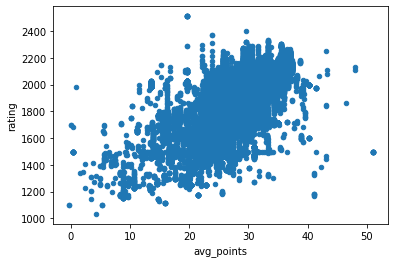

In [ ]:
final_train2.plot.scatter(x='avg_points',y='rating')

In [ ]:
turns1 = turns[(turns['points'] >= 50)]

In [ ]:
turns1[turns1['nickname'].isin(['BetterBot','HastyBot','STEEBot']) == False]

,game_id,turn_number,nickname,rack,location,move,points,score,turn_type
7,1,8,stevy,AEEFIRS,9B,FAERIES,72,137,Play
13,1,14,stevy,??DEEIV,O8,rElIVED,98,296,Play
35,2,9,Super,ACEGIST,L6,CAGIEST,94,229,Play
43,2,17,Super,CDEEILN,O1,DECLINE.,89,391,Play
51,2,25,Super,?AOORST,1D,RATOOnS,73,486,Play
...,...,...,...,...,...,...,...,...,...
2005462,72772,21,Gtowngrad,AEORSSU,K9,AROUSES,67,265,Play
2005468,72772,27,Gtowngrad,?EOPRTT,2D,POTT.REr,63,377,Play
2005477,72773,6,adola,AEOORTZ,L1,ZOOEA,53,94,Play
2005479,72773,8,adola,?EEFNRT,M3,FERmENT,90,184,Play


In [ ]:
final_train2[final_train2['nickname'].isin(turns1[turns1['nickname'].isin(['BetterBot','HastyBot','STEEBot']) == False]['nickname'])]['rating'].value_counts()

1500.0    7560
1979.0     215
1590.0     189
1840.0     184
1579.0     182
          ... 
2310.0       1
2299.0       1
2404.0       1
1190.0       1
1186.0       1
Name: rating, Length: 1117, dtype: int64

In [ ]:
final_train2['rating'].value_counts()

1500.0    7575
1979.0     216
1590.0     189
1840.0     184
1579.0     182
          ... 
1193.0       1
1165.0       1
1156.0       1
1199.0       1
1186.0       1
Name: rating, Length: 1135, dtype: int64

In [ ]:
"""
1500 숫자 어떻게 할지 회의에서 논의

내일까지:
BINGO (50점 넘는 경우 회숫를 nickname 별로 기록)
point --> 해결 완료
test data --> 똑같은 처리 적용
"""

In [ ]:
final_train2.to_csv(r'/content/drive/MyDrive/KUBIG 2022 이수찬/2차 분류 예측 프로젝트/final_train2.csv')
final_test2.to_csv(r'/content/drive/MyDrive/KUBIG 2022 이수찬/2차 분류 예측 프로젝트/final_test2.csv')